In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%pip install scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /Users/vyasbodke/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
df=pd.read_csv("WeatherAUS.csv")

In [3]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


In [5]:
df.isnull().sum()

Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

In [6]:
df=df.drop(['Sunshine','Evaporation','Cloud9am','Cloud3pm','WindGustDir','WindDir9am','WindDir3pm'],axis=1)

removed some columns of string values as advised and other columns cause they have around 50 percent null values so median cant be filled accurately

In [7]:
df.describe()

,MinTemp,MaxTemp,Rainfall,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,16.990631,21.68339
std,6.398495,7.119049,8.478060,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,40.200000,46.70000


found no problems with errors not matching the columns name definition or negative values like in humidity percentage is required and other values also which cant be negative

<Axes: xlabel='Rainfall'>

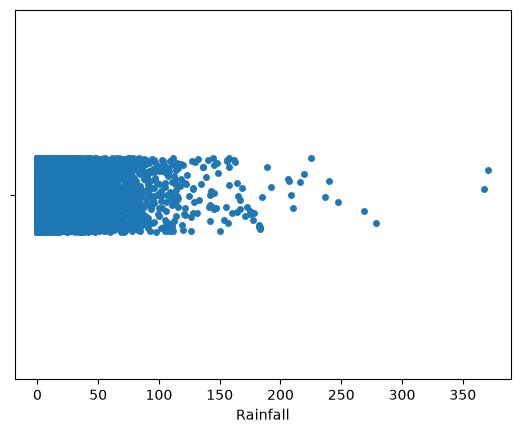

In [8]:
sns.stripplot(data=df, x="Rainfall")

will do rainfall separtely than others becuase values are not seeming right, so changing value of k as 5 
instead of 1.5 experimental


In [9]:

rain = df["Rainfall"].where(df["Rainfall"] > 0)
groups = rain.groupby(df["Location"])

q1 = groups.transform(lambda x: x.quantile(0.25))
q3 = groups.transform(lambda x: x.quantile(0.75))
iqr = q3 - q1

upper = q3 + 5 * iqr


outliers = (
    (df["Rainfall"] > upper)
    & (iqr > 0)
)

print("Rainfall values replaced:", outliers.sum())
df.loc[outliers, "Rainfall"] = np.nan

Rainfall values replaced: 1018


<Axes: xlabel='Rainfall'>

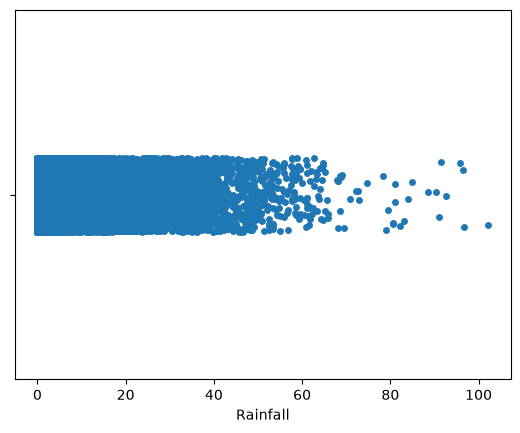

In [10]:
sns.stripplot(data=df, x="Rainfall")

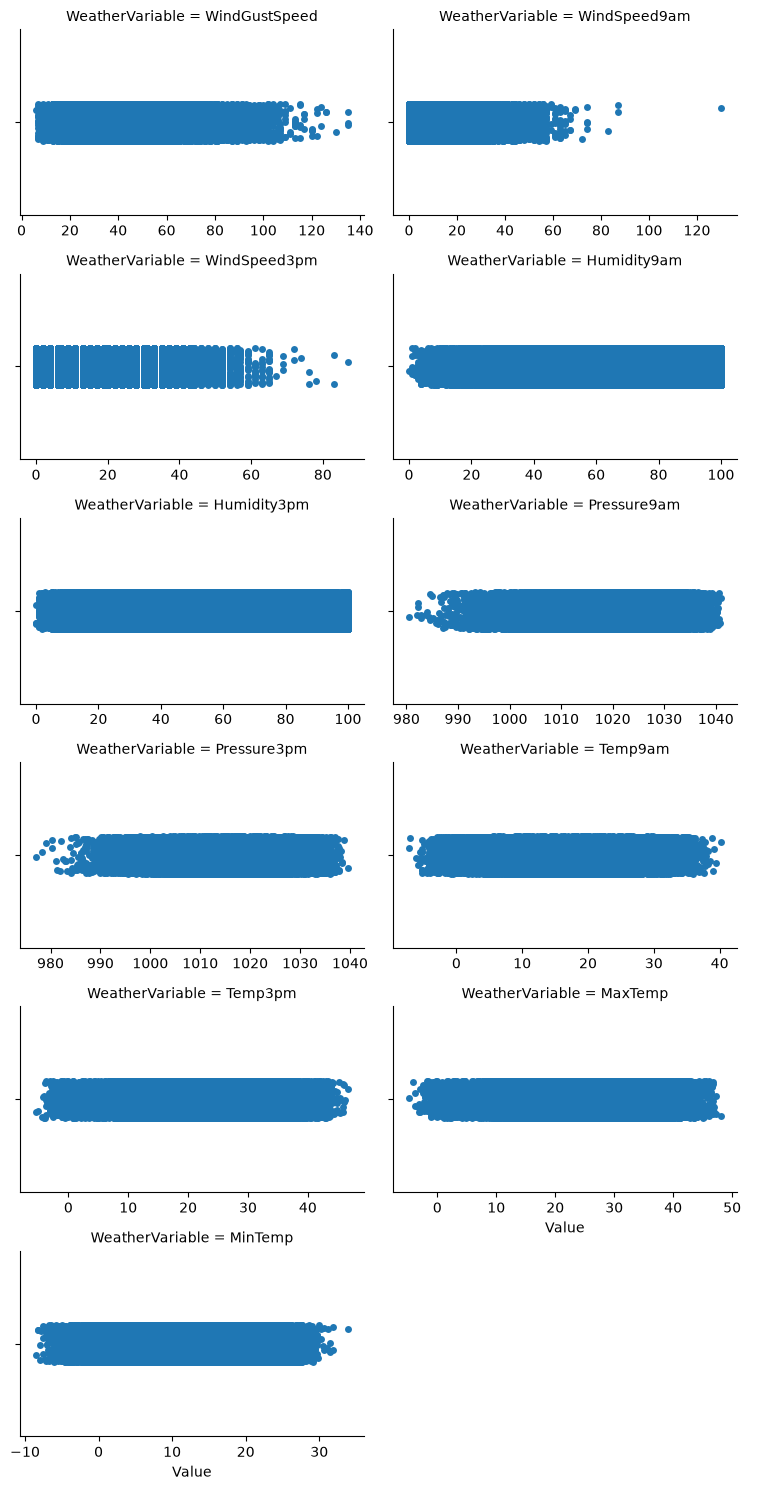

In [11]:
cols = ["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm", 
        "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm", 
        "Temp9am", "Temp3pm","MaxTemp","MinTemp"]


df_melted = df.melt(value_vars=cols, var_name='WeatherVariable', value_name='Value')


sns.catplot(
    data=df_melted, 
    x='Value', 
    col='WeatherVariable', 
    col_wrap=2,      
    sharex=False, height=2.5, aspect=1.5     
    
)

plt.tight_layout()
plt.show()

In [12]:

for col in cols:
    group=df[col].groupby(df["Location"])
    q1 = group.transform(lambda x: x.quantile(0.25))
    q3 = group.transform(lambda x: x.quantile(0.75))
    iqr=q3-q1

    low=q1-1.5*iqr
    up=q3+1.5*iqr
    print("low=",low,"up=",up)

    outliers=((df[col]<low)|(df[col]>up))&(iqr>0)

    print(col, "values replaced", outliers.sum())
    df.loc[outliers, col] = np.nan

low= 0         -1.5
1         -1.5
2         -1.5
3         -1.5
4         -1.5
          ... 
145455    10.5
145456    10.5
145457    10.5
145458    10.5
145459    10.5
Name: WindGustSpeed, Length: 145460, dtype: float64 up= 0         66.5
1         66.5
2         66.5
3         66.5
4         66.5
          ... 
145455    70.5
145456    70.5
145457    70.5
145458    70.5
145459    70.5
Name: WindGustSpeed, Length: 145460, dtype: float64
WindGustSpeed values replaced 2587
low= 0        -6.5
1        -6.5
2        -6.5
3        -6.5
4        -6.5
         ... 
145455   -8.5
145456   -8.5
145457   -8.5
145458   -8.5
145459   -8.5
Name: WindSpeed9am, Length: 145460, dtype: float64 up= 0         21.5
1         21.5
2         21.5
3         21.5
4         21.5
          ... 
145455    43.5
145456    43.5
145457    43.5
145458    43.5
145459    43.5
Name: WindSpeed9am, Length: 145460, dtype: float64
WindSpeed9am values replaced 2576
low= 0        -6.0
1        -6.0
2        -6.0
3        -6

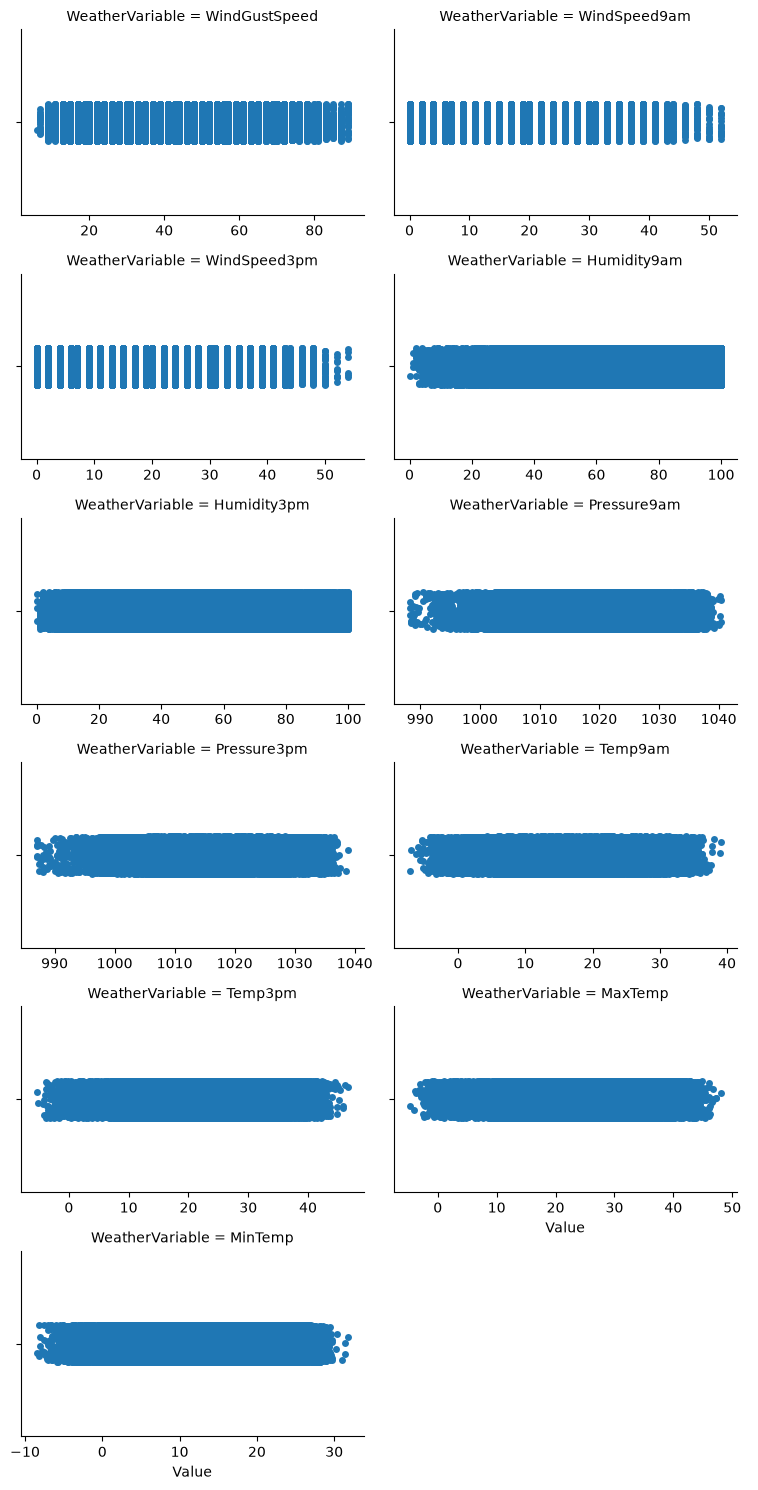

In [13]:
df_melted = df.melt(
    value_vars=cols,
    var_name="WeatherVariable",
    value_name="Value"
)

sns.catplot(
    data=df_melted,
    x="Value",
    col="WeatherVariable",
    col_wrap=2,
    kind="strip",
    sharex=False,
    height=2.5,
    aspect=1.5
)

plt.show()

Encoding the yes no data using 1 and 0

In [14]:
mapping = {'No': 0, 'Yes': 1}

df['RainToday'] = df['RainToday'].map(mapping)
df['RainTomorrow'] = df['RainTomorrow'].map(mapping)

In [15]:
df.isnull().sum()

Date                 0
Location             0
MinTemp           1883
MaxTemp           2300
Rainfall          4279
WindGustSpeed    12850
WindSpeed9am      4343
WindSpeed3pm      4939
Humidity9am       3573
Humidity3pm       7088
Pressure9am      15856
Pressure3pm      15843
Temp9am           2664
Temp3pm           4569
RainToday         3261
RainTomorrow      3267
dtype: int64

In [16]:

rain_medians = df.groupby("RainToday")["Rainfall"].median()
print(rain_medians)


mask = df["Rainfall"].isna() & df["RainToday"].notna()

df.loc[mask, "Rainfall"] = (df.loc[mask, "RainToday"].map(rain_medians))

RainToday
0.0    0.0
1.0    5.0
Name: Rainfall, dtype: float64


Using rain today data to fill rainfall

In [17]:
mask = df["RainToday"].isna() & df["Rainfall"].notna()

df.loc[mask, "RainToday"] = (df.loc[mask, "Rainfall"] > 1).astype(int)

In [18]:
df.isnull().sum()

Date                 0
Location             0
MinTemp           1883
MaxTemp           2300
Rainfall          3261
WindGustSpeed    12850
WindSpeed9am      4343
WindSpeed3pm      4939
Humidity9am       3573
Humidity3pm       7088
Pressure9am      15856
Pressure3pm      15843
Temp9am           2664
Temp3pm           4569
RainToday         3261
RainTomorrow      3267
dtype: int64

In [19]:
df = df.dropna(subset=["RainTomorrow"]).copy()

rain_today_mode = df["RainToday"].mode()[0]
df["RainToday"] = df["RainToday"].fillna(rain_today_mode)

df["Rainfall"] = df["Rainfall"].fillna(df["RainToday"].map(rain_medians))




Using Rainfall data to fill raintoday

In [20]:
df.isnull().sum()

Date                 0
Location             0
MinTemp           1033
MaxTemp           1352
Rainfall             0
WindGustSpeed    11807
WindSpeed9am      3866
WindSpeed3pm      4465
Humidity9am       2679
Humidity3pm       6126
Pressure9am      14780
Pressure3pm      14777
Temp9am           1793
Temp3pm           3674
RainToday            0
RainTomorrow         0
dtype: int64

Filling normal median as no more relations I can find

In [21]:
df[cols] = df[cols].fillna(df[cols].median())

df.isnull().sum()

Date             0
Location         0
MinTemp          0
MaxTemp          0
Rainfall         0
WindGustSpeed    0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Temp9am          0
Temp3pm          0
RainToday        0
RainTomorrow     0
dtype: int64

In [22]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
    dtype=int
)

encoded_locations = encoder.fit_transform(df[["Location"]])

location_df = pd.DataFrame(
    encoded_locations,
    columns=encoder.get_feature_names_out(["Location"]),
    index=df.index
)

df = pd.concat(
    [df.drop(columns=["Location"]), location_df],
    axis=1
)

Encoding Location data here

In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Date", "RainTomorrow"])
y = df["RainTomorrow"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

Splitting the data before scaling as per site kaggle

In [24]:
from sklearn.preprocessing import StandardScaler

scale_cols = [
    "MinTemp", "MaxTemp", "Rainfall",
    "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm",
    "Humidity9am", "Humidity3pm",
    "Pressure9am", "Pressure3pm",
    "Temp9am", "Temp3pm"
]

scaler = StandardScaler()

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

Scaling data as per kaggle site

In [25]:
X_train[scale_cols].agg(["mean", "std"]).round(2)

,MinTemp,MaxTemp,Rainfall,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Temp9am,Temp3pm
mean,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


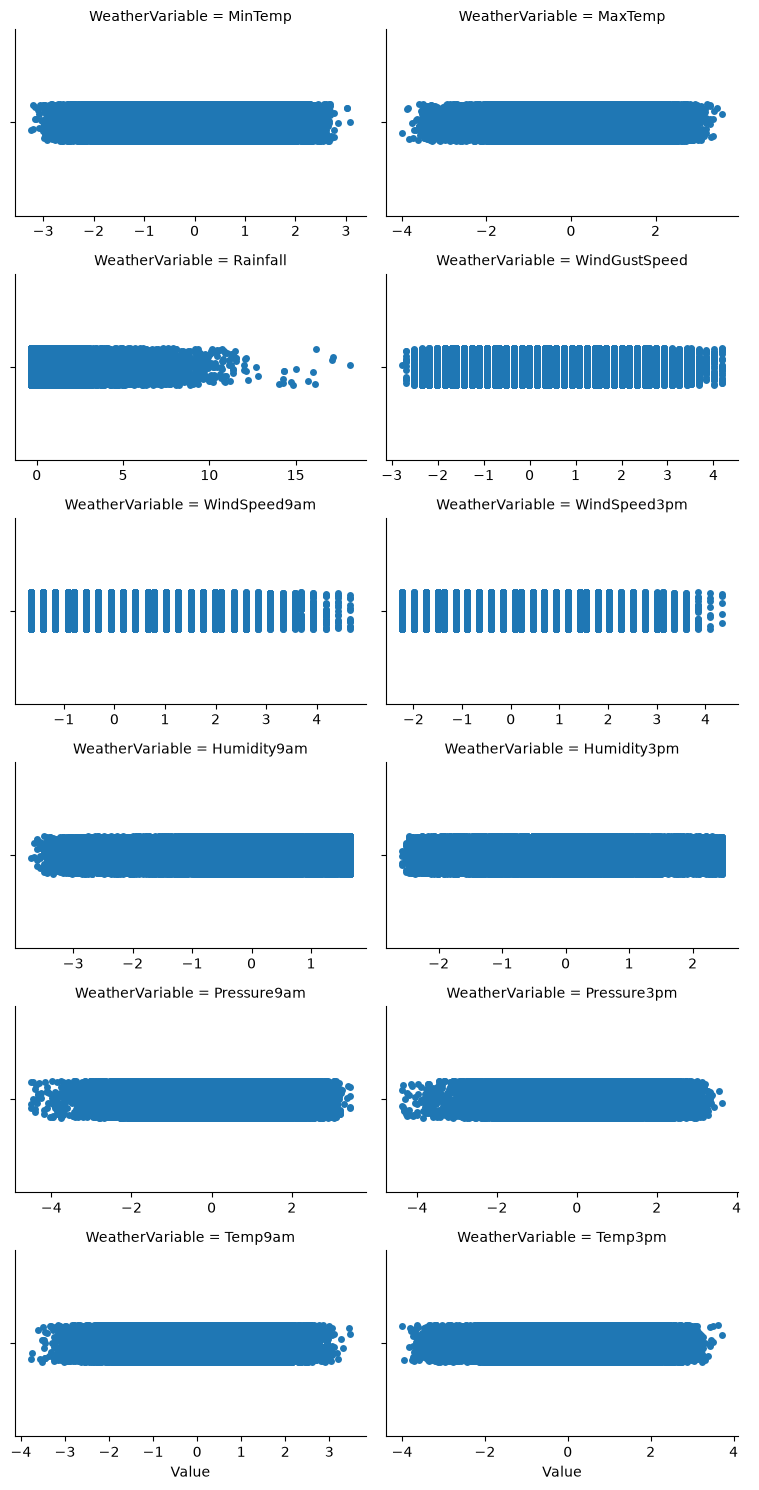

In [26]:

df_melted = X_train.melt(
    value_vars=scale_cols,
    var_name="WeatherVariable",
    value_name="Value"
)


sns.catplot(
    data=df_melted, 
    x='Value', 
    col='WeatherVariable', 
    col_wrap=2,      
    sharex=False, height=2.5, aspect=1.5     
    
)

plt.tight_layout()
plt.show()

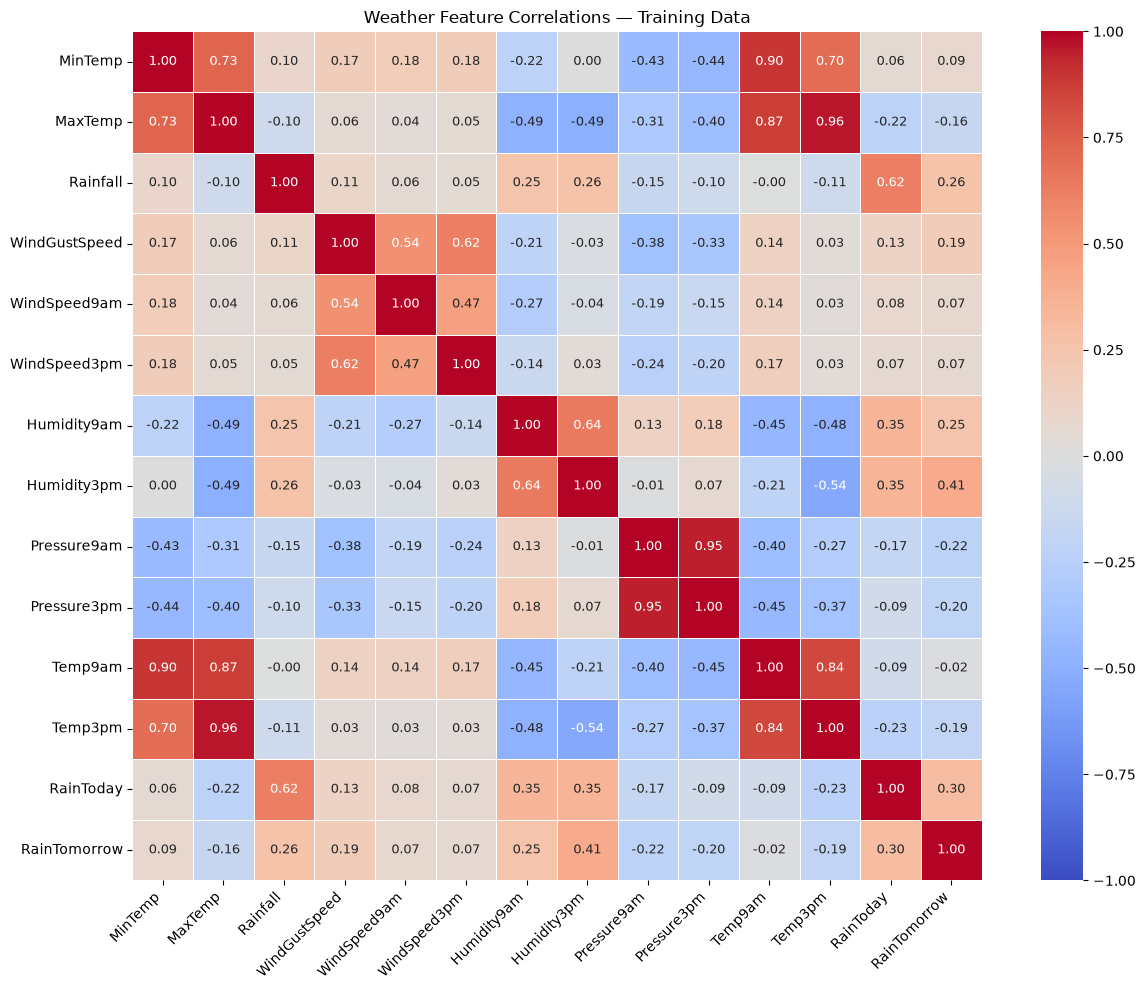

In [28]:
# Select weather features for plotting
plot_data = X_train[scale_cols + ["RainToday"]].copy()
plot_data["RainTomorrow"] = y_train

corr = plot_data.corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 9}
)

plt.title("Weather Feature Correlations — Training Data")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()